# Classificador Distância Mínima ao Centroide (DMC)

*Implementação em numpy · base original (sem pré-processamento)*

Cada classe $i$ é representada pelo centroide $\mathbf{m}_i$ (vetor médio das suas amostras de treino). A amostra é atribuída à classe do centroide mais próximo pela distância euclidiana:

$$\hat{y}(\mathbf{x}) = \arg\min_i \|\mathbf{x} - \mathbf{m}_i\|_2$$

Protocolo (OBS 1–4 do enunciado): 100 rodadas treino-teste independentes e estratificadas para cada separação 20/80, 30/70, 50/50, 70/30 e 80/20.

## Dados

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # antes do numpy: evita falta de memória do OpenBLAS no Windows

import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
from avaliacao import (SPLITS, carregar, avaliar, estatisticas, matrizes_confusao, grafico_splits,
                       por_classe, grafico_por_classe, resumo, salvar)

pd.set_option("display.max_rows", 200)

X, y, classes = carregar(processada=False)
print(f"{len(y)} instâncias | {X.shape[1]} atributos | {len(classes)} classes: {list(classes)}")

5456 instâncias | 4 atributos | 4 classes: ['Move-Forward', 'Sharp-Right-Turn', 'Slight-Left-Turn', 'Slight-Right-Turn']


## Modelo

In [2]:
class DistanciaMinimaCentroide:
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.centroides_ = np.array([X[y == c].mean(axis=0) for c in self.classes_])  # média por classe
        return self

    def predict(self, X):
        d = ((X[:, None, :] - self.centroides_[None]) ** 2).sum(axis=2)  # distância euclidiana ao quadrado
        return self.classes_[d.argmin(axis=1)]


MODELOS = {"DMC": DistanciaMinimaCentroide()}

## Execução
100 rodadas × 5 separações. Em cada rodada, todos os modelos usam a mesma divisão treino/teste.

In [3]:
res, confusoes = avaliar(MODELOS, X, y, classes)
salvar(res, "classification", "distancia_minima_centroide")

## OBS 1 e 2 — Estatísticas de acurácia e tempos de treinamento/teste (ms)

In [4]:
estatisticas(res).round(4)

,,média,desvio,máxima,mínima,mediana,t_treino_ms,t_teste_ms
split,modelo,,,,,,,
20/80,DMC,0.6088,0.0221,0.6969,0.5732,0.6053,0.1578,0.5787
30/70,DMC,0.6078,0.0150,0.6551,0.5724,0.6078,0.2098,0.5373
50/50,DMC,0.6041,0.0105,0.6284,0.5790,0.6035,0.3324,0.4528
70/30,DMC,0.6033,0.0113,0.6369,0.5733,0.6024,0.3992,0.2608
80/20,DMC,0.6019,0.0132,0.6471,0.5665,0.6017,0.4304,0.2000


## OBS 2 — Matrizes de confusão da melhor e da pior rodada

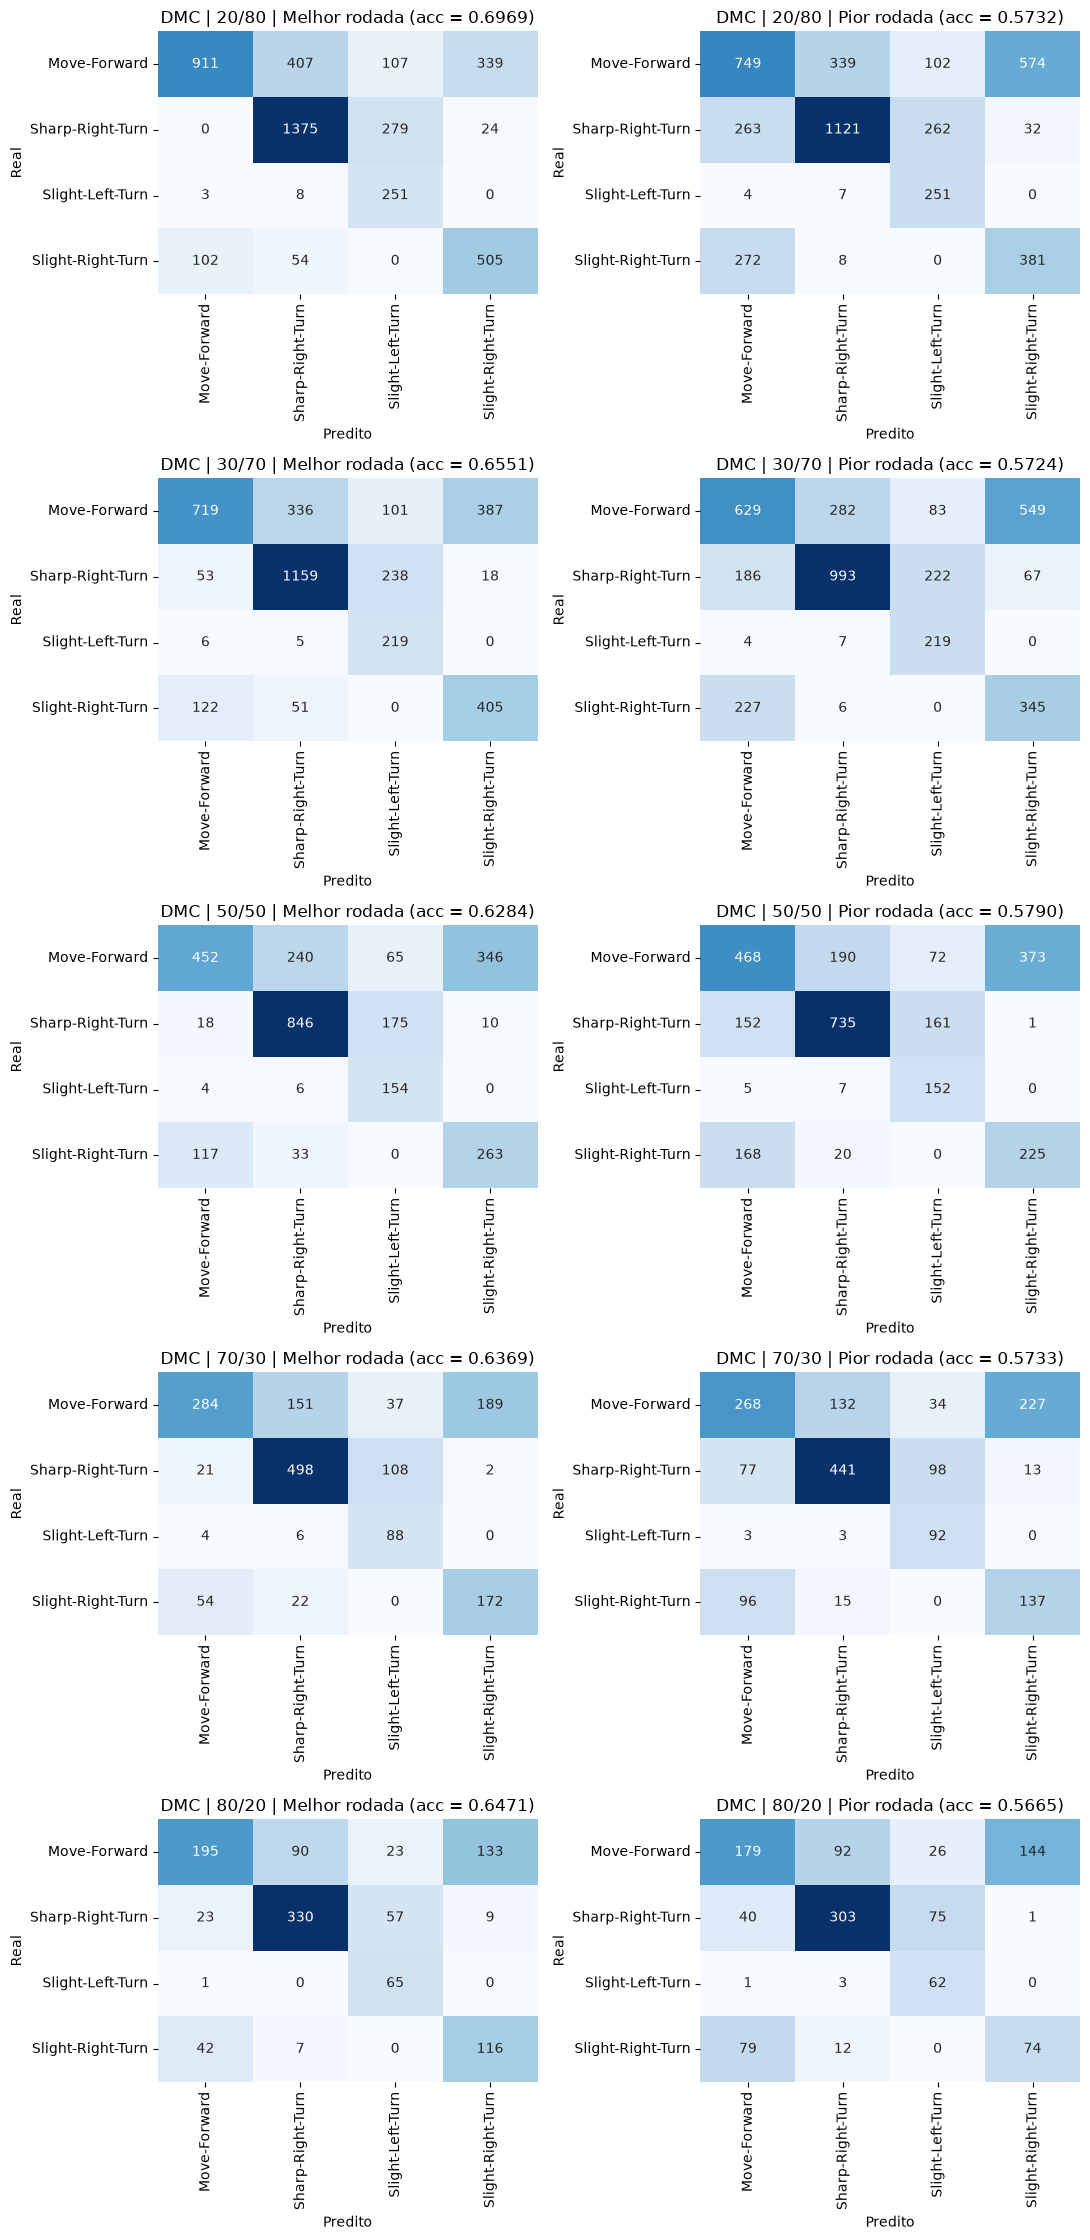

In [5]:
matrizes_confusao(res, confusoes, classes, splits=SPLITS)

## OBS 3 — Efeito da separação treino/teste

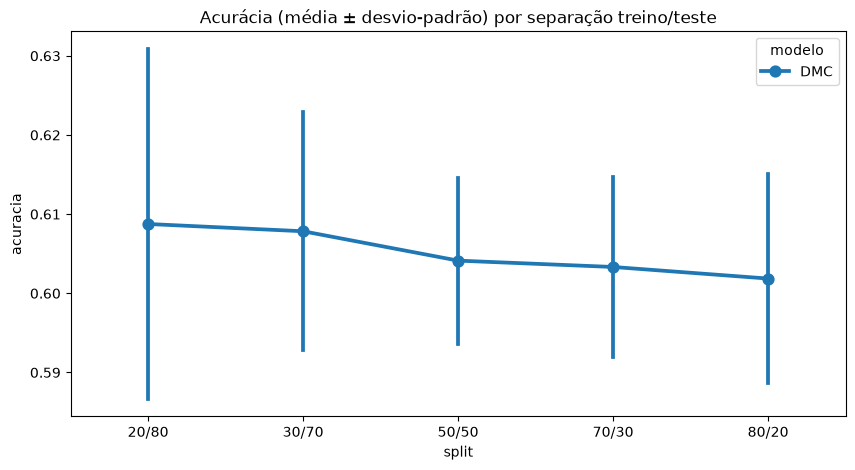

In [6]:
grafico_splits(res)

## OBS 4 — Desempenho por classe (taxa de acerto de cada classe)

In [7]:
por_classe(res, classes).round(4)

média  desvio  máxima  mínima  mediana
classe            split modelo                                         
Move-Forward      20/80 DMC     0.4250  0.0373  0.5544  0.3413   0.4175
                  30/70 DMC     0.4131  0.0231  0.5126  0.3506   0.4080
                  50/50 DMC     0.4115  0.0111  0.4343  0.3844   0.4116
                  70/30 DMC     0.4147  0.0157  0.4539  0.3767   0.4160
                  80/20 DMC     0.4100  0.0220  0.4671  0.3583   0.4104
Sharp-Right-Turn  20/80 DMC     0.7587  0.0393  0.8355  0.6657   0.7527
                  30/70 DMC     0.7652  0.0315  0.8317  0.6764   0.7592
                  50/50 DMC     0.7586  0.0212  0.8151  0.7007   0.7541
                  70/30 DMC     0.7546  0.0177  0.8060  0.7011   0.7552
                  80/20 DMC     0.7548  0.0150  0.7900  0.7017   0.7566
Slight-Left-Turn  20/80 DMC     0.9533  0.0053  0.9656  0.9427   0.9542
                  30/70 DMC     0.9540  0.0081  0.9783  0.9391   0.9522
                  50/50 DMC     0.9543  0.0125  0.9878  0.9146   0.9573
                  70/30 DMC     0.9530  0.0168  1.0000  0.8980   0.9490
                  80/20 DMC     0.9520  0.0213  1.0000  0.8939   0.9545
Slight-Right-Turn 20/80 DMC     0.5819  0.0740  0.7912  0.4660   0.5734
                  30/70 DMC     0.5901  0.0569  0.7785  0.4637   0.5848
                  50/50 DMC     0.5871  0.0421  0.7554  0.4915   0.5884
                  70/30 DMC     0.5843  0.0367  0.7016  0.5040   0.5887
                  80/20 DMC     0.5861  0.0459  0.7030  0.4485   0.5879

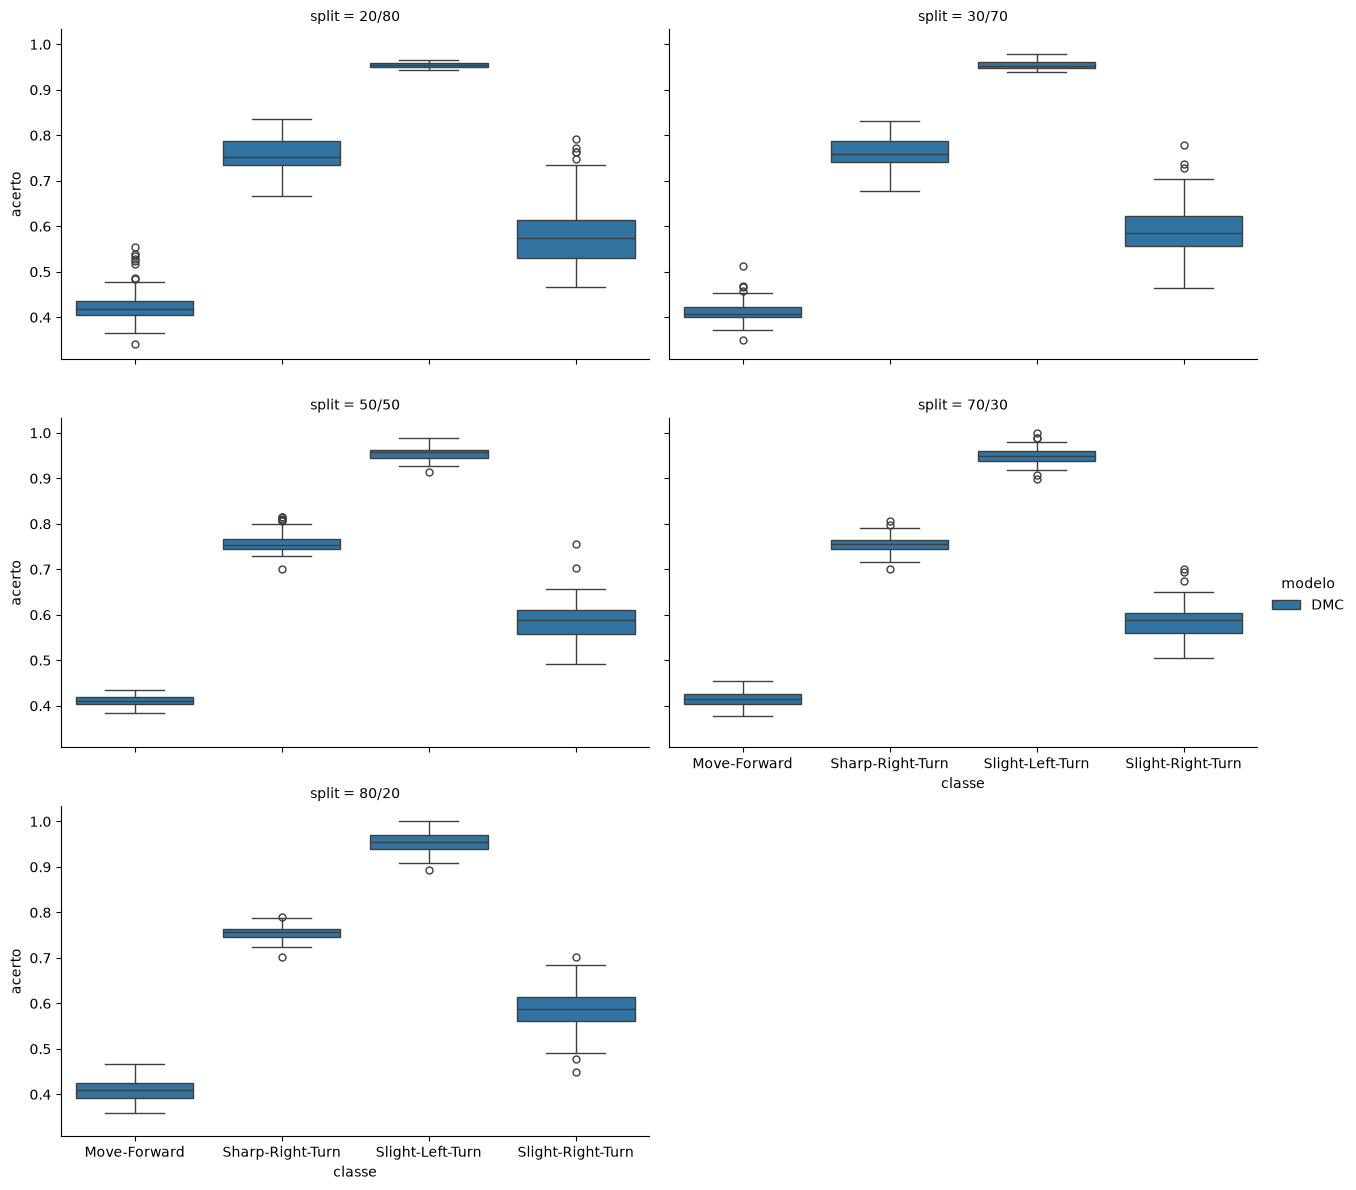

In [8]:
grafico_por_classe(res, classes)

## Resumo dos resultados

In [9]:
resumo(res, classes)

Melhor configuração: DMC com split 20/80 -> acurácia média 0.6088

Tempo médio por rodada (ms):
  DMC: treino 0.306 | teste 0.406

Efeito do split (acurácia média 20/80 -> 80/20):
  DMC: 0.6088 -> 0.6019 (-0.0069)

Taxa de acerto média por classe (todas as rodadas):
  Move-Forward: 0.4149
  Slight-Right-Turn: 0.5859
  Sharp-Right-Turn: 0.7584
  Slight-Left-Turn: 0.9533
Classe mais fácil: Slight-Left-Turn | mais difícil: Move-Forward
